# 22 – XGBoost: Welche Fehlerart steckt dahinter, und was heißt das für jede Station?

**Zweck:** Die Notebooks 18 bis 21 haben je eine Sicht auf die Stationen geliefert —
Kennzahlen, ein gelerntes Embedding, die Abweichungen des Wächters. Hier kommen alle
zusammen in **ein** Modell je Fehlerart. Drei Fragen:

1. **Welche Fehlerarten lassen sich aus den Daten vor der Begehung überhaupt erkennen?**
2. **Bringen Baum-Modelle (Random Forest, XGBoost) und Wechselwirkungen zwischen
   Merkmalen mehr als eine logistische Regression?**
3. **Was heißt das für jede einzelne der 96 Stationen** — auch die nie begangenen? Die
   Antwort sind die drei Klassen aus Folie 5.

| Notebook | liefert |
|---|---|
| [`18_modelldaten`](18_modelldaten_labels.ipynb) | 13 Kennzahlen je Zähler (vor der Begehung), 6 Labels |
| [`19_kmeans`](19_kmeans_einstufung_folie5.ipynb) | Einstufung Optimum / schlechter |
| [`20_lstm`](20_lstm_fehlererkennung.ipynb) | LSTM-Embedding Winter 23/24 und Sommer 2024 |
| [`21_prognose`](21_prognose_lstm_waechter.ipynb) | Abweichungen des Wächters je Tag |

**Ergebnis:** `fehlerklassen_je_hast.csv` — Klasse nach Folie 5 und Hinweise je Zähler.

## 1 · Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"
SEED = 0
print(f"XGBoost {xgboost.__version__}")

XGBoost 3.4.1


**Was macht diese Zelle?**
- Lädt die drei Modellfamilien: logistische Regression, Random Forest (scikit-learn) und
  XGBoost (Gradient Boosting auf Entscheidungsbäumen).

## 2 · Eine Tabelle mit allen Merkmalen

Je Zähler eine Zeile, drei Gruppen von Spalten. Vom Wächter werden nur Tage **vor** der
Begehung genommen, und nur solche, die er nicht zum Lernen benutzt hat (Validierung und
Sommer 2024).

In [2]:
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler").drop(columns=["stunden_winter", "stunden_sommer"])
emb = pd.read_csv(PROCESSED / "lstm_embedding.csv", index_col="zaehler").filter(regex="lstm_(w2324|s2024)_")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
kmeans = pd.read_csv(PROCESSED / "kmeans_einstufung.csv", index_col="zaehler")
prog = pd.read_csv(PROCESSED / "prognose_tage.csv", parse_dates=["tag"])

vorher = prog[prog["abschnitt"].isin(["Validierung", "Test (Sommer 2024)"])].copy()
vorher["auffaellig"] = (vorher["z_rl"].abs() >= 3) | (vorher["z_fluss"].abs() >= 3)
waechter = vorher.groupby("zaehler").agg(
    waechter_res_rl=("res_rl", "mean"),
    waechter_res_fluss_nacht=("res_fluss_nacht", "mean"),
    waechter_anteil_auffaellig=("auffaellig", "mean"))

merkmale = kz.join(emb).join(waechter)
GRUPPEN = {
    "Kennzahlen (Notebook 18)": list(kz.columns),
    "LSTM-Embedding (Notebook 20)": list(emb.columns),
    "Wächter (Notebook 21)": list(waechter.columns),
}
pd.DataFrame({"Spalten": {g: len(s) for g, s in GRUPPEN.items()},
              "Zähler mit Werten": {g: int(merkmale[s].notna().all(axis=1).sum()) for g, s in GRUPPEN.items()}})

,Spalten,Zähler mit Werten
Kennzahlen (Notebook 18),13,62
LSTM-Embedding (Notebook 20),16,81
Wächter (Notebook 21),3,67


In [3]:
merkmale.round(2).head()

,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,lstm_w2324_z0,lstm_w2324_z1,lstm_w2324_z2,lstm_w2324_z3,lstm_w2324_z4,lstm_w2324_z5,lstm_w2324_z6,lstm_w2324_z7,lstm_s2024_z0,lstm_s2024_z1,lstm_s2024_z2,lstm_s2024_z3,lstm_s2024_z4,lstm_s2024_z5,lstm_s2024_z6,lstm_s2024_z7,waechter_res_rl,waechter_res_fluss_nacht,waechter_anteil_auffaellig
zaehler,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
41704231,0.0,0.00,NaN,34.41,NaN,40.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.63,0.62,1.03,-1.19,-0.22,0.13,0.16,1.91,-0.78,0.50,0.49,-0.94,0.14,0.10,0.18,1.57,-0.14,-0.01,0.02
41704232,0.0,0.00,NaN,35.77,NaN,42.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.76,0.69,0.96,-1.28,-0.21,0.13,0.17,2.00,-0.69,0.49,0.54,-0.72,0.12,0.20,0.15,1.43,-0.25,-0.02,0.47
53198226,10.0,0.66,14.2,44.78,32.07,54.5,0.65,0.34,0.1,0.96,0.83,42.95,1.31,-0.27,0.16,0.02,0.12,-0.22,-0.19,-0.31,-1.01,-1.20,0.19,-0.21,0.11,0.41,-0.05,0.47,-0.49,0.32,-10.29,0.02
58177363,NaN,NaN,NaN,42.14,32.33,47.6,0.62,0.62,NaN,0.84,0.60,39.22,NaN,-0.34,0.39,0.40,0.12,-0.44,-0.27,-0.42,-0.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,1.55,0.04
58177384,NaN,NaN,NaN,57.14,25.31,57.5,0.47,0.58,NaN,1.17,0.59,51.06,NaN,-0.35,0.05,-0.22,-0.34,-0.05,-0.37,-0.13,-0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.27,13.33,0.12


**Was machen die beiden Zellen?**
- Fügen die drei Quellen per Zählernummer zusammen: 13 Kennzahlen, 16 Embedding-Zahlen
  (Winter und Sommer), 3 Zusammenfassungen des Wächters:

| Wächter-Merkmal | Bedeutung |
|---|---|
| `waechter_res_rl` | Wie viel wärmer kam der Rücklauf zurück, als das Netz erwartet hat (Mittel, K)? |
| `waechter_res_fluss_nacht` | Wie viel mehr floss nachts, als erwartet (l/h)? |
| `waechter_anteil_auffaellig` | An welchem Anteil der Tage lag ein z-Wert über 3? |

- Fehlende Werte (z. B. Zähler, die der Wächter nicht kennt) werden später **im Lernteil**
  mit dem Median gefüllt; XGBoost kann mit Lücken selbst umgehen.

## 3 · Die Modelle

| Modell | wie es entscheidet | Wechselwirkungen? |
|---|---|---|
| **Logistische Regression** | gewichtete Summe der Merkmale | nein |
| **Random Forest** | Mehrheit aus 300 tiefen, zufällig variierten Bäumen | ja |
| **XGBoost, Tiefe 1** | Summe vieler Bäume mit nur **einer** Frage je Baum | **nein**, jeder Baum sieht nur ein Merkmal |
| **XGBoost, Tiefe 2–3** | Summe vieler Bäume mit 2–3 Fragen hintereinander | **ja**, z. B. „hoher Rücklauf *und* wenig Spreizung“ |

Der Vergleich Tiefe 1 gegen Tiefe 2–3 beantwortet direkt die Frage, ob
**Wechselwirkungen** zwischen Merkmalen etwas bringen — alles andere ist gleich.

Alle Modelle gewichten die seltene Klasse hoch (bei XGBoost über `scale_pos_weight`,
das in jedem Lernteil neu berechnet wird), und alle werden wie in Notebook 20
**verschachtelt** geprüft: Die Hyperparameter wählt eine innere 4-fache Kreuzvalidierung
nur auf dem Lernteil.

In [4]:
class XGBAusgeglichen(XGBClassifier):
    # XGBoost, das die seltene Klasse in jedem Lernteil neu gewichtet
    def fit(self, X, y, **kwargs):
        self.set_params(scale_pos_weight=(len(y) - np.sum(y)) / max(np.sum(y), 1))
        return super().fit(X, y, **kwargs)


def modell(name):
    if name == "Logistische Regression":
        return (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(class_weight="balanced", max_iter=5000)),
                {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]})
    if name == "Random Forest":
        return (make_pipeline(SimpleImputer(strategy="median"),
                              RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=1)),
                {"randomforestclassifier__max_depth": [2, 4, None], "randomforestclassifier__min_samples_leaf": [2, 5]})
    tiefen = [1] if name == "XGBoost Tiefe 1" else [2, 3]
    return (XGBAusgeglichen(subsample=0.8, colsample_bytree=0.8, min_child_weight=2, n_jobs=1, random_state=SEED, verbosity=0),
            {"max_depth": tiefen, "learning_rate": [0.05, 0.15], "n_estimators": [100, 300]})


def verschachtelt(name, X, y, gruppen=None):
    schaetzer, raster = modell(name)
    suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
    aussen = LeaveOneOut() if gruppen is None else LeaveOneGroupOut()
    return cross_val_predict(suche, X, y, cv=aussen, groups=gruppen, method="predict_proba", n_jobs=-1)[:, 1]


def auc_mit_intervall(y, score, n=2000):
    rng = np.random.default_rng(SEED)
    ziehungen = [roc_auc_score(y[i], score[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n)) if 0 < y[i].sum() < len(i)]
    return roc_auc_score(y, score), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def auc_differenz(y, a, b, n=2000):
    rng = np.random.default_rng(SEED)
    ziehungen = [roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n)) if 0 < y[i].sum() < len(i)]
    return roc_auc_score(y, a) - roc_auc_score(y, b), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def precision_at_k(y, score, k=10):
    return y[np.argsort(-score)[:k]].mean()

**Was macht diese Zelle?**
- `XGBAusgeglichen` ist XGBoost mit einer Zeile mehr: Vor jedem Lernen wird das Gewicht der
  seltenen Klasse aus dem aktuellen Lernteil berechnet (Anzahl Nein / Anzahl Ja).
- `modell()` liefert je Modell die Pipeline und das Raster der Hyperparameter, das innen
  durchsucht wird.
- `verschachtelt()`, `auc_mit_intervall()`, `auc_differenz()` und `precision_at_k()` sind
  dieselben Werkzeuge wie in Notebook 20.

## 4 · Alle Fehlerarten, alle Modelle

Gerechnet werden sechs Kombinationen je Fehlerart, jeweils einmal mit einzelnen Stationen
ausgelassen (Leave-one-out) und einmal mit ganzen Straßen. Als Bezug dient die
logistische Regression **nur auf den Kennzahlen** — das, was man ohne neuronale Netze
hätte. Wo es eine physikalische Faustregel gibt, steht sie als **Regel ohne Lernen**
daneben:

* Ventil: Anteil der Sommernächte mit Durchfluss (wie in Notebook 20),
* Überdimensioniert: **niedrige Auslastung** (Spitzenlast / Anschlusswert).

Geprüft wird auf derselben Basis wie in Notebook 20: begangene Zähler mit
Winter-Embedding und Sommerwerten. Das dauert einige Minuten.

In [5]:
ZIELE = ["ventil", "daemmung", "ueberdimensioniert", "filter", "durchfluss", "temperatur"]
KENNZAHLEN = GRUPPEN["Kennzahlen (Notebook 18)"]
MERKMALSSAETZE = {
    "nur Kennzahlen": KENNZAHLEN,
    "Kennzahlen + LSTM": KENNZAHLEN + GRUPPEN["LSTM-Embedding (Notebook 20)"],
    "alle Merkmale": [s for spalten in GRUPPEN.values() for s in spalten],
}
ALLE = MERKMALSSAETZE["alle Merkmale"]
KOMBIS = [
    ("Logistische Regression", "nur Kennzahlen"),
    ("Logistische Regression", "Kennzahlen + LSTM"),
    ("Logistische Regression", "alle Merkmale"),
    ("Random Forest", "alle Merkmale"),
    ("XGBoost Tiefe 1", "alle Merkmale"),
    ("XGBoost Tiefe 2–3", "alle Merkmale"),
]
REGELN = {"ventil": ("sommer_durchlauf_anteil", +1), "ueberdimensioniert": ("auslastung", -1)}
SPLITS = {"Station ausgelassen": None, "Straße ausgelassen": "strasse_gruppe"}

daten = labels.join(merkmale, how="inner")
daten = daten.dropna(subset=[c for c in emb.columns if "w2324" in c] + ["sommer_durchlauf_anteil"])
print(f"Prüfbasis: {len(daten)} begangene Zähler (wie Notebook 20)")

scores, zeilen = {}, []
for ziel in ZIELE:
    d = daten.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    if min(y.sum(), len(y) - y.sum()) < 5:
        zeilen.append({"Ziel": ziel, "Modell": "nicht modellierbar", "n": len(y), "Fälle": int(y.sum())})
        continue
    for split, gruppe in SPLITS.items():
        gruppen = None if gruppe is None else d[gruppe].to_numpy()
        kandidaten = [(name, satz, None) for name, satz in KOMBIS]
        if ziel in REGELN:
            kandidaten.insert(0, ("Regel ohne Lernen", REGELN[ziel][0], REGELN[ziel]))
        for name, satz, regel in kandidaten:
            if regel:
                spalte, richtung = regel
                s = (richtung * d[spalte].fillna(d[spalte].median())).to_numpy()     # fehlender Wert = Median
            else:
                s = verschachtelt(name, d[MERKMALSSAETZE[satz]], y, gruppen)
            scores[(ziel, split, name, satz)] = s
            auc, unten, oben = auc_mit_intervall(y, s)
            zeilen.append({"Ziel": ziel, "Split": split, "Modell": name, "Merkmale": satz, "n": len(y), "Fälle": int(y.sum()),
                           "AUC": auc, "unten": unten, "oben": oben, "P@10": precision_at_k(y, s)})
ergebnis = pd.DataFrame(zeilen)
loo = ergebnis[ergebnis["Split"] == "Station ausgelassen"]
loo.round(2)

Prüfbasis: 53 begangene Zähler (wie Notebook 20)


,Ziel,Split,Modell,Merkmale,n,Fälle,AUC,unten,oben,P@10
0,ventil,Station ausgelassen,Regel ohne Lernen,sommer_durchlauf_anteil,53,11,0.85,0.68,0.98,0.7
1,ventil,Station ausgelassen,Logistische Regression,nur Kennzahlen,53,11,0.79,0.57,0.97,0.6
2,ventil,Station ausgelassen,Logistische Regression,Kennzahlen + LSTM,53,11,0.89,0.78,0.98,0.8
3,ventil,Station ausgelassen,Logistische Regression,alle Merkmale,53,11,0.85,0.71,0.96,0.6
4,ventil,Station ausgelassen,Random Forest,alle Merkmale,53,11,0.84,0.68,0.97,0.6
5,ventil,Station ausgelassen,XGBoost Tiefe 1,alle Merkmale,53,11,0.78,0.60,0.92,0.5
6,ventil,Station ausgelassen,XGBoost Tiefe 2–3,alle Merkmale,53,11,0.81,0.65,0.94,0.6
14,daemmung,Station ausgelassen,Logistische Regression,nur Kennzahlen,53,22,0.68,0.52,0.84,0.9
15,daemmung,Station ausgelassen,Logistische Regression,Kennzahlen + LSTM,53,22,0.77,0.62,0.90,0.9
16,daemmung,Station ausgelassen,Logistische Regression,alle Merkmale,53,22,0.76,0.61,0.89,0.9


**Was macht diese Zelle?**
- Für jede Fehlerart mit mindestens 5 Fällen und 5 Gegenfällen: sechs Kombinationen aus Modell
  und Merkmalen (und gegebenenfalls die Regel), zwei Arten auszulassen, je eine verschachtelte
  Prüfung. Die Regel braucht kein Lernen; sie sortiert die Stationen nur nach einer Kennzahl.
- Die Tabelle zeigt die Variante „Station ausgelassen“. `n` ist die Zahl der begangenen Zähler
  mit bekanntem Label, `Fälle` die Zahl mit Befund.

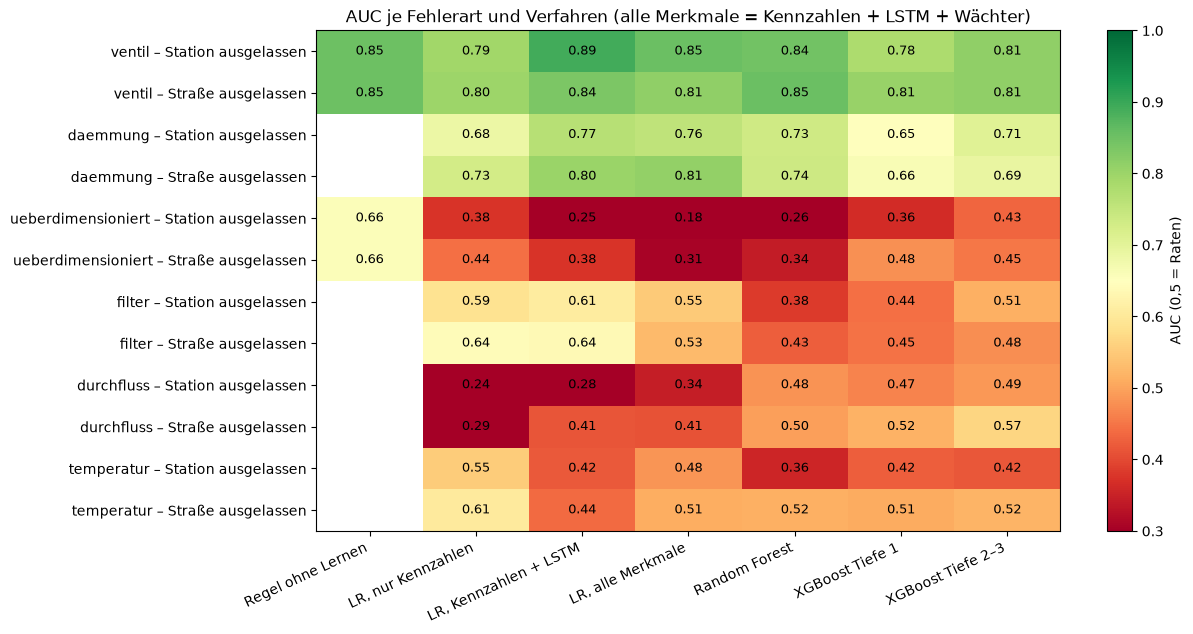

In [6]:
ergebnis["Verfahren"] = np.where(ergebnis["Modell"] == "Logistische Regression",
                                  "LR, " + ergebnis["Merkmale"].astype(str), ergebnis["Modell"])
spalten = ["Regel ohne Lernen", "LR, nur Kennzahlen", "LR, Kennzahlen + LSTM", "LR, alle Merkmale",
           "Random Forest", "XGBoost Tiefe 1", "XGBoost Tiefe 2–3"]
tafel = ergebnis.dropna(subset=["AUC"]).pivot_table(index=["Ziel", "Split"], columns="Verfahren", values="AUC")
tafel = tafel.reindex(columns=spalten).reindex(ZIELE, level=0)
fig, ax = plt.subplots(figsize=(12, 6.5))
bild = ax.imshow(tafel.to_numpy(dtype=float), cmap="RdYlGn", vmin=0.3, vmax=1.0, aspect="auto")
ax.set_xticks(range(tafel.shape[1]), tafel.columns, rotation=25, ha="right")
ax.set_yticks(range(tafel.shape[0]), [f"{z} – {s}" for z, s in tafel.index])
for i in range(tafel.shape[0]):
    for j in range(tafel.shape[1]):
        if pd.notna(tafel.iloc[i, j]):
            ax.text(j, i, f"{tafel.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(bild, label="AUC (0,5 = Raten)")
ax.set_title("AUC je Fehlerart und Verfahren (alle Merkmale = Kennzahlen + LSTM + Wächter)")
plt.show()

**Was macht diese Zelle?**
- Fasst alle Ergebnisse in einem Bild zusammen: Zeilen sind Fehlerart und Art des Auslassens,
  Spalten die Verfahren. Grün ist gut, Gelb um 0,5 ist Raten. Leere Felder: Für diese
  Fehlerart gibt es keine Faustregel.

**Ergebnis**

**Erkennbar sind zwei Fehlerarten:**

| Fehlerart | bestes Verfahren | AUC Station | AUC Straße | P@10 |
|---|---|---|---|---|
| **Ventil** (11 von 53) | LR, Kennzahlen + LSTM | 0,89 [0,78; 0,98] | 0,84 | 8 von 10 |
| **Dämmung** (22 von 53) | LR, Kennzahlen + LSTM | 0,77 [0,62; 0,90] | 0,80 | 9 von 10 |

- Beim Ventil ist die Sommernacht-Regel ohne Lernen fast gleich gut (0,85). Der Gewinn des LSTM liegt im Winter (Notebook 20).
- **Die Baum-Modelle sind nirgends besser** als die logistische Regression: Random Forest kommt beim Ventil auf 0,84, XGBoost auf 0,78 bis 0,81. Bei 53 Stationen und 32 Merkmalen finden Bäume eher Zufallsmuster, eine gewichtete Summe ist robuster.
- **Die Wächter-Merkmale helfen nicht:** Mit ihnen sinkt die AUC leicht (Ventil 0,85 statt 0,89, Dämmung 0,76 statt 0,77). Der Wächter ist für neue Veränderungen gebaut, nicht für Dauerzustände.

**Nicht erkennbar sind vier Fehlerarten:**

- **Überdimensioniert:** Die Regel „niedrige Auslastung“ kommt auf 0,66, ihr Intervall reicht aber bis 0,37. Alle gelernten Modelle liegen unter 0,5. Mit 35 Stationen und 32 Merkmalen lernen sie Rauschen. Der Zusammenhang, den die Auslastung andeutet, geht dabei unter.
- **Filter, Durchfluss, Temperatur:** Alle Verfahren liegen zwischen 0,24 und 0,64, also im Bereich von Raten (siehe den Zufallstest unten). Notebook 18 hat den wahrscheinlichen Grund gezeigt: Bei Filter und Durchfluss gibt es kaum ausdrückliche „nein“, und die Temperatur wurde fast überall gesenkt.

## 5 · Was ist belegt?

Gepaarte Bootstrap-Differenzen (wie in Notebook 20) auf den Stationen-Splits:

* jedes Verfahren gegen die **logistische Regression auf den Kennzahlen**,
* **XGBoost mit Wechselwirkungen (Tiefe 2–3) gegen ohne (Tiefe 1)**.

In [7]:
zeilen = []
split = "Station ausgelassen"
for ziel in ZIELE:
    if (ziel, split, "Logistische Regression", "nur Kennzahlen") not in scores:
        continue
    y = daten.dropna(subset=[ziel])[ziel].astype(int).to_numpy()
    bezug = scores[(ziel, split, "Logistische Regression", "nur Kennzahlen")]
    vergleiche = [(f"{n}, {s}" if n == "Logistische Regression" else n, scores[(ziel, split, n, s)], "LR, nur Kennzahlen", bezug)
                  for (z, sp, n, s) in scores if z == ziel and sp == split and s != "nur Kennzahlen"]
    vergleiche.append(("XGBoost Tiefe 2–3", scores[(ziel, split, "XGBoost Tiefe 2–3", "alle Merkmale")],
                       "XGBoost Tiefe 1", scores[(ziel, split, "XGBoost Tiefe 1", "alle Merkmale")]))
    for name, a, gegen, b in vergleiche:
        d, unten, oben = auc_differenz(y, a, b)
        zeilen.append({"Ziel": ziel, "Verfahren": name, "gegen": gegen, "Differenz": d, "unten": unten, "oben": oben,
                       "belegt": "besser" if unten > 0 else "schlechter" if oben < 0 else "–"})
differenzen = pd.DataFrame(zeilen)
differenzen.round(2)

,Ziel,Verfahren,gegen,Differenz,unten,oben,belegt
0,ventil,Regel ohne Lernen,"LR, nur Kennzahlen",0.06,-0.02,0.15,–
1,ventil,"Logistische Regression, Kennzahlen + LSTM","LR, nur Kennzahlen",0.10,-0.02,0.26,–
2,ventil,"Logistische Regression, alle Merkmale","LR, nur Kennzahlen",0.06,-0.03,0.19,–
3,ventil,Random Forest,"LR, nur Kennzahlen",0.05,-0.04,0.20,–
4,ventil,XGBoost Tiefe 1,"LR, nur Kennzahlen",-0.01,-0.15,0.12,–
5,ventil,XGBoost Tiefe 2–3,"LR, nur Kennzahlen",0.02,-0.12,0.18,–
6,ventil,XGBoost Tiefe 2–3,XGBoost Tiefe 1,0.03,-0.01,0.09,–
7,daemmung,"Logistische Regression, Kennzahlen + LSTM","LR, nur Kennzahlen",0.08,-0.02,0.21,–
8,daemmung,"Logistische Regression, alle Merkmale","LR, nur Kennzahlen",0.07,-0.06,0.22,–
9,daemmung,Random Forest,"LR, nur Kennzahlen",0.05,-0.11,0.22,–


**Was macht diese Zelle?**
- Rechnet je Fehlerart die gepaarten Differenzen. „besser“ bzw. „schlechter“ steht nur, wenn
  das 95-%-Intervall die 0 ausschließt.

**Ergebnis**

- **Bei Ventil und Dämmung ist kein Verfahren belegt besser als die logistische Regression auf den Kennzahlen.** Am nächsten dran: Kennzahlen + LSTM mit +0,10 (Ventil) bzw. +0,08 (Dämmung), beide Intervalle beginnen knapp unter 0. Das ist dasselbe Bild wie in Notebook 20.
- **Wechselwirkungen bringen nichts Belegtes:** XGBoost mit Tiefe 2–3 liegt beim Ventil 0,03, bei der Dämmung 0,05 über Tiefe 1. Beides ist nicht abgesichert. Die einzige „belegte“ Verbesserung (Filter, +0,07) hebt XGBoost von 0,44 auf 0,51, also von Raten auf Raten.
- **Die übrigen belegten Unterschiede** betreffen nur Fehlerarten, die ohnehin nicht erkennbar sind. Beim Durchfluss sind die Bäume „besser“, weil die logistische Regression dort auf 0,24 liegt und die Bäume bei 0,48. Nützlich ist keins von beiden.

### Wie weit streut die AUC bei reinem Zufall?

Einige AUCs liegen deutlich **unter** 0,5, beim Durchfluss bis 0,24. Heißt das, die
Modelle liegen systematisch falsch herum? Die Gegenprobe: Die Durchfluss-Labels werden
20-mal zufällig vertauscht — dann gibt es sicher keinen Zusammenhang — und jedes Mal wird
genau dieselbe verschachtelte Prüfung gerechnet.

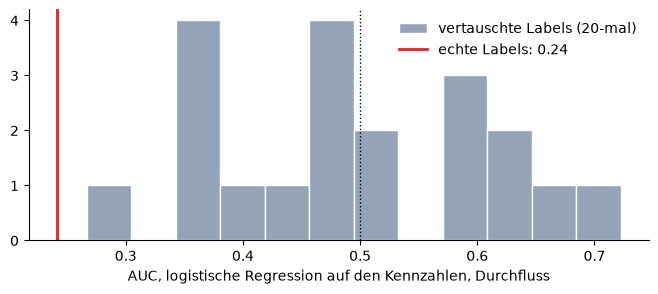

Vertauschte Labels: AUC im Mittel 0.50, Spanne 0.27 bis 0.72


In [8]:
d = daten.dropna(subset=["durchfluss"])
y_echt = d["durchfluss"].astype(int).to_numpy()
rng = np.random.default_rng(SEED)
zufall = [roc_auc_score(y_z, verschachtelt("Logistische Regression", d[KENNZAHLEN], y_z))
          for y_z in (rng.permutation(y_echt) for _ in range(20))]
echt = roc_auc_score(y_echt, scores[("durchfluss", split, "Logistische Regression", "nur Kennzahlen")])

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(zufall, bins=12, color="#94A3B8", edgecolor="white", label="vertauschte Labels (20-mal)")
ax.axvline(echt, color="#DC2626", lw=2, label=f"echte Labels: {echt:.2f}")
ax.axvline(0.5, color="black", ls=":", lw=1)
ax.set_xlabel("AUC, logistische Regression auf den Kennzahlen, Durchfluss")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"Vertauschte Labels: AUC im Mittel {np.mean(zufall):.2f}, Spanne {np.min(zufall):.2f} bis {np.max(zufall):.2f}")

**Was macht diese Zelle?**
- Vertauscht die Labels zufällig (`rng.permutation`), sodass jeder Zusammenhang zu den
  Merkmalen zerstört ist, und rechnet die verschachtelte Prüfung 20-mal.
- Das Histogramm zeigt, welche AUCs bei reinem Zufall herauskommen; die rote Linie den Wert
  mit den echten Labels.

**Ergebnis**

- Bei vertauschten Labels liegt die AUC im Mittel bei 0,50, wie es sein muss. Sie **streut aber von 0,27 bis 0,72**, und jede vierte Ziehung liegt unter 0,4. Bei 53 Stationen sind Werte weit weg von 0,5 also auch ohne jeden Zusammenhang normal. Darum steht hinter jeder AUC in diesem Projekt ein Intervall.
- Der echte Wert (0,24) liegt **unter allen 20 Zufallswerten**. Es gibt also einen schwachen *umgekehrten* Zusammenhang: Wo der Durchfluss eingestellt wurde, sahen die Kennzahlen vorher eher unauffällig aus. Vielleicht wurde gerade an gut laufenden Stationen hydraulisch nachgeregelt. Bei 6 Fehlerarten und 7 Verfahren ist ein einzelner Ausreißer dieser Größe aber nicht überraschend. Zur Erkennung taugt das nicht.

## 6 · Worauf schaut XGBoost? SHAP-Werte und Wechselwirkungen

**SHAP-Werte** zerlegen jede einzelne Vorhersage in Beiträge der Merkmale: Wie viel hat
dieses Merkmal die Vorhersage für diese Station nach oben oder unten geschoben? Der
Mittelwert der Beträge über alle Stationen ist die Wichtigkeit des Merkmals. XGBoost
rechnet das selbst (`pred_contribs=True`), auch die Beiträge von **Merkmalspaaren**
(`pred_interactions=True`).

Dafür wird je Fehlerart ein XGBoost (Tiefe 2, damit Paare überhaupt vorkommen können) auf
**allen** begangenen Stationen gelernt. Das ist eine Beschreibung des Modells, keine
Prüfung — die steht in Abschnitt 4.

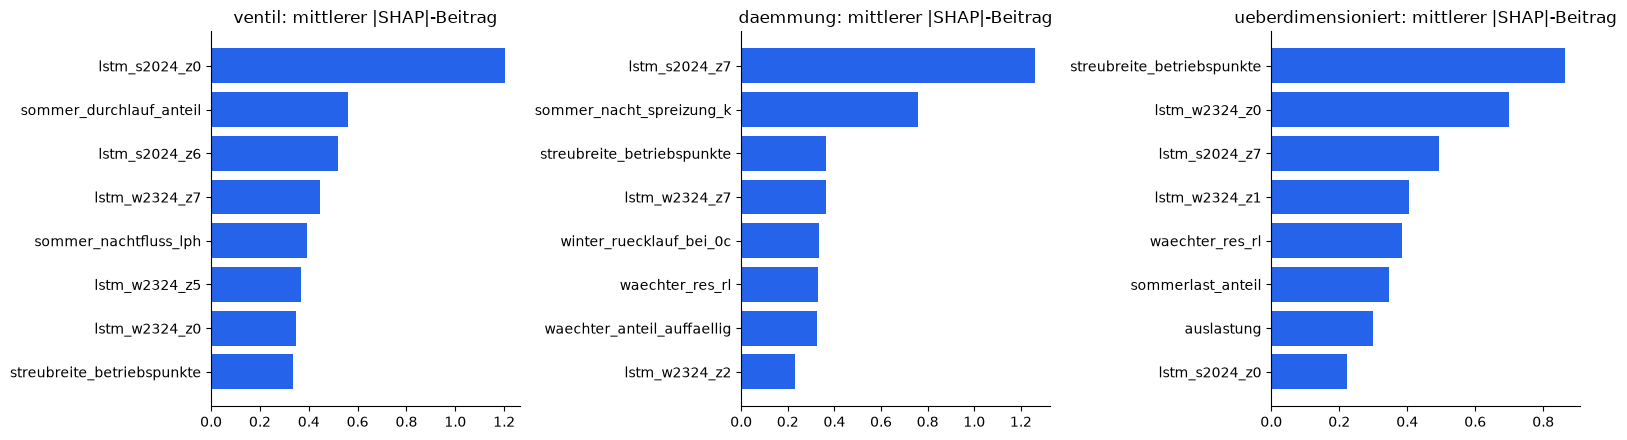

,Ziel,Merkmal A,Merkmal B,mittlerer |Beitrag| des Paares
0,ventil,streubreite_betriebspunkte,lstm_s2024_z0,0.135
1,ventil,lstm_w2324_z5,lstm_s2024_z0,0.075
2,ventil,lstm_s2024_z6,lstm_s2024_z0,0.069
3,daemmung,sommer_nacht_spreizung_k,lstm_s2024_z7,0.125
4,daemmung,winter_ruecklauf_bei_0c,lstm_w2324_z5,0.067
5,daemmung,lstm_s2024_z7,lstm_s2024_z5,0.065
6,ueberdimensioniert,lstm_s2024_z7,lstm_w2324_z0,0.078
7,ueberdimensioniert,streubreite_betriebspunkte,lstm_s2024_z7,0.066
8,ueberdimensioniert,sommerlast_anteil,waechter_res_fluss_nacht,0.042


In [9]:
ERKLAEREN = ["ventil", "daemmung", "ueberdimensioniert"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
paare = []
for ax, ziel in zip(axes, ERKLAEREN):
    d = daten.dropna(subset=[ziel])
    X, y = d[ALLE], d[ziel].astype(int).to_numpy()
    xgb = XGBAusgeglichen(max_depth=2, learning_rate=0.05, n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                          min_child_weight=2, n_jobs=1, random_state=SEED, verbosity=0).fit(X, y)
    matrix = xgboost.DMatrix(X, missing=np.nan)
    beitraege = xgb.get_booster().predict(matrix, pred_contribs=True)[:, :-1]
    wichtig = pd.Series(np.abs(beitraege).mean(axis=0), index=ALLE).sort_values().tail(8)
    ax.barh(wichtig.index, wichtig.values, color="#2563EB")
    ax.set_title(f"{ziel}: mittlerer |SHAP|-Beitrag")
    ax.spines[["top", "right"]].set_visible(False)

    inter = np.abs(xgb.get_booster().predict(matrix, pred_interactions=True)[:, :-1, :-1]).mean(axis=0)
    np.fill_diagonal(inter, 0)
    i, j = np.unravel_index(np.argsort(inter, axis=None)[::-1][:6:2], inter.shape)   # symmetrisch: jedes Paar steht zweimal
    for a, b in zip(i, j):
        paare.append({"Ziel": ziel, "Merkmal A": ALLE[a], "Merkmal B": ALLE[b], "mittlerer |Beitrag| des Paares": 2 * inter[a, b]})
fig.tight_layout()
plt.show()
pd.DataFrame(paare).round(3)

**Was macht diese Zelle?**
- Lernt je Fehlerart ein XGBoost auf allen begangenen Stationen und lässt sich die SHAP-Beiträge
  ausgeben. Die Balken zeigen die acht wichtigsten Merkmale.
- Die Tabelle zeigt je Fehlerart die drei stärksten **Paare**: Wie viel trägt das Zusammenspiel
  zweier Merkmale bei, über ihre Einzelwirkung hinaus?

**Was XGBoost nutzt**

- **Ventil:** Mit Abstand am wichtigsten ist die erste Zahl des **Sommer-Embeddings** (`lstm_s2024_z0`), danach der Durchlaufanteil in Sommernächten. Das Netz hat in einer seiner acht Zahlen genau das Bild „nachts läuft Wasser durch“ gefunden, ohne dass ihm jemand gesagt hat, worauf es ankommt.
- **Dämmung:** Vorne liegen eine Sommer-Embedding-Zahl (`lstm_s2024_z7`) und die **Spreizung in Sommernächten**. Das passt zur Physik: Ungedämmte Leitungen geben auch nachts Wärme ab, das wenige durchfließende Wasser kühlt dabei ab, und die Spreizung steigt, obwohl niemand heizt. Danach folgen Rücklauf bei 0 °C und die Rücklauf-Abweichung des Wächters.
- **Wechselwirkungen:** Die stärksten Paare (z. B. Streubreite × Sommer-Embedding beim Ventil) tragen im Mittel 0,1 bis 0,15 bei, die wichtigsten Einzelmerkmale über 1. Wechselwirkungen spielen also eine Nebenrolle, wie es auch Abschnitt 5 gezeigt hat.
- **Überdimensioniert:** Das Bild beschreibt ein Modell, das sich nicht verallgemeinern lässt (AUC unter 0,5). Es zeigt, worauf XGBoost sich eingestellt hat, nicht was in den Daten steckt.

## 7 · Kurztest: Hilft es, die seltene Klasse anders zu gewichten?

Alle Modelle oben gewichten die seltene Klasse hoch. Ist das nötig? Verglichen wird die
logistische Regression auf allen Merkmalen mit und ohne Gewichtung. Neben der AUC zählt
hier der **Brier-Score**: der mittlere quadratische Abstand zwischen vorhergesagter
Wahrscheinlichkeit und tatsächlichem Befund (kleiner ist besser). Er zeigt, ob die
Wahrscheinlichkeiten **stimmen**, nicht nur ihre Reihenfolge.

In [10]:
zeilen = []
for ziel in ("ventil", "daemmung"):
    d = daten.dropna(subset=[ziel])
    X, y = d[ALLE], d[ziel].astype(int).to_numpy()
    for gewicht in ("balanced", None):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(class_weight=gewicht, max_iter=5000))
        suche = GridSearchCV(pipe, {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]}, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
        p = cross_val_predict(suche, X, y, cv=LeaveOneOut(), method="predict_proba", n_jobs=-1)[:, 1]
        zeilen.append({"Ziel": ziel, "Gewichtung": "ausgeglichen" if gewicht else "keine", "AUC": roc_auc_score(y, p),
                       "Brier": brier_score_loss(y, p), "mittlere Wahrscheinlichkeit": p.mean(), "tatsächlicher Anteil": y.mean()})
pd.DataFrame(zeilen).round(3)

,Ziel,Gewichtung,AUC,Brier,mittlere Wahrscheinlichkeit,tatsächlicher Anteil
0,ventil,ausgeglichen,0.853,0.143,0.357,0.208
1,ventil,keine,0.861,0.111,0.210,0.208
2,daemmung,ausgeglichen,0.757,0.192,0.485,0.415
3,daemmung,keine,0.748,0.189,0.441,0.415


**Was macht diese Zelle?**
- Rechnet die logistische Regression zweimal, einmal mit `class_weight="balanced"` und einmal
  ohne, sonst identisch.
- Vergleicht die mittlere vorhergesagte Wahrscheinlichkeit mit dem tatsächlichen Anteil: Bei
  gut kalibrierten Wahrscheinlichkeiten liegen beide nah beieinander.

**Ergebnis**

- **Die Reihenfolge der Stationen ändert sich kaum:** Ventil 0,85 mit gegen 0,86 ohne Gewichtung, Dämmung 0,76 gegen 0,75.
- **Die Wahrscheinlichkeiten schon:** Mit Gewichtung sagt das Modell beim Ventil im Mittel 36 % voraus, obwohl nur 21 % der Stationen einen Befund hatten. Ohne Gewichtung sind es 21 %, und der Brier-Score ist besser (0,11 statt 0,14).
- Das ist ein **Negativbefund**: Den Klassen ein anderes Gewicht zu geben, hilft bei diesen Daten nicht beim Finden. Es macht nur die Wahrscheinlichkeiten zu hoch. In der Vorarbeit zeigte sich dasselbe für Over- und Undersampling und SMOTE. Nur bei XGBoost war die Gewichtung dort nötig, weil es ohne sie die seltene Klasse fast ignorierte.
- Für die Klassen unten spielt das keine Rolle: Die Schwelle wird aus der Kreuzvalidierung bestimmt und passt sich an die Lage der Wahrscheinlichkeiten an.

## 8 · Die drei Klassen der Folie 5 — für jede Station

Jetzt wird zusammengesetzt, in der Reihenfolge, die Notebook 19 nahegelegt hat:

1. **Regelventil tauschen**, wenn das Ventil-Modell die Station über seiner Schwelle sieht;
2. sonst **Regelparameter optimieren**, wenn K-Means die Station als „schlechter“ einstuft;
3. sonst **kein Handlungsbedarf**.

Für das Ventil wird das **gelernte** Verfahren mit der besten AUC aus Abschnitt 4 genommen
— nicht die Sommernacht-Regel, denn die kann nur urteilen, wenn es Sommerdaten gibt.
Die **Schwelle** kommt aus der Kreuzvalidierung: der Punkt, an dem Trefferquote minus
Fehlalarmquote am größten ist (Youden-Index).

Für **begangene** Stationen stammt der Wert aus der Kreuzvalidierung — das Modell hat
diese Station beim Lernen nie gesehen. Für **nie begangene** kommt er aus einem Modell,
das auf allen begangenen Stationen gelernt hat.

Dazu kommen **Hinweise** auf Dämmung und Überdimensionierung, nach demselben Verfahren —
aber nur, wenn das beste Verfahren **belegt besser als Raten** ist (untere Grenze des
AUC-Intervalls über 0,5). Ein Hinweis aus einem Modell, das nicht besser rät als eine
Münze, wäre irreführend.

In [11]:
def endmodell(ziel, nur_gelernt=False):
    t = loo[loo["Ziel"] == ziel]
    if nur_gelernt:
        t = t[t["Modell"] != "Regel ohne Lernen"]
    t = t.sort_values("AUC", ascending=False).iloc[0]
    d = daten.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    oof = pd.Series(scores[(ziel, split, t["Modell"], t["Merkmale"])], index=d.index)
    fpr, tpr, schwellen = roc_curve(y, oof)
    schwelle = schwellen[np.argmax(tpr - fpr)]
    if t["Modell"] == "Regel ohne Lernen":
        spalte, richtung = REGELN[ziel]
        wert = richtung * merkmale[spalte].fillna(daten[spalte].median())
    else:
        spalten = MERKMALSSAETZE[t["Merkmale"]]
        schaetzer, raster = modell(t["Modell"])
        suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc").fit(d[spalten], y)
        wert = pd.Series(suche.predict_proba(merkmale[spalten])[:, 1], index=merkmale.index)
        wert.loc[oof.index] = oof                      # begangene: Wert aus der Kreuzvalidierung
    belegt = t["unten"] > 0.5
    print(f"{ziel:18s} {t['Modell']} ({t['Merkmale']}): AUC {t['AUC']:.2f} [{t['unten']:.2f}; {t['oben']:.2f}], "
          f"Schwelle {schwelle:.2f}{'' if belegt else '  -> nicht belegt besser als Raten, kein Hinweis'}")
    return wert, schwelle, belegt


p_ventil, s_ventil, _ = endmodell("ventil", nur_gelernt=True)
w_daemmung, s_daemmung, daemmung_belegt = endmodell("daemmung")
w_vertrag, s_vertrag, vertrag_belegt = endmodell("ueberdimensioniert")

klassen = pd.DataFrame({"p_ventil": p_ventil})
klassen["kmeans"] = kmeans["einstufung"].reindex(klassen.index)
klassen["begangen"] = klassen.index.isin(labels.index)
klassen["klasse"] = np.select(
    [klassen["p_ventil"] >= s_ventil, klassen["kmeans"] == "schlechter", klassen["kmeans"] == "Optimum"],
    ["Regelventil tauschen", "Regelparameter optimieren", "kein Handlungsbedarf"], "nicht einstufbar")
klassen["hinweis_daemmung"] = (w_daemmung >= s_daemmung) if daemmung_belegt else np.nan
klassen["hinweis_vertrag"] = (w_vertrag >= s_vertrag) if vertrag_belegt else np.nan
pd.crosstab(klassen["klasse"], klassen["begangen"].map({True: "begangen", False: "nie begangen"}), margins=True, margins_name="Summe")

ventil             Logistische Regression (Kennzahlen + LSTM): AUC 0.89 [0.78; 0.98], Schwelle 0.68
daemmung           Logistische Regression (Kennzahlen + LSTM): AUC 0.77 [0.62; 0.90], Schwelle 0.57
ueberdimensioniert Regel ohne Lernen (auslastung): AUC 0.66 [0.37; 0.92], Schwelle -0.84  -> nicht belegt besser als Raten, kein Hinweis


begangen,begangen,nie begangen,Summe
klasse,,,
Regelparameter optimieren,4,5,9
Regelventil tauschen,10,9,19
kein Handlungsbedarf,40,23,63
nicht einstufbar,2,3,5
Summe,56,40,96


**Was macht diese Zelle?**
- `endmodell()` nimmt das beste Verfahren aus Abschnitt 4 (fürs Ventil nur gelernte),
  bestimmt die Schwelle aus den Werten der Kreuzvalidierung, lernt das Modell auf allen
  begangenen Stationen neu und bewertet damit alle 96 Zähler. Für begangene Zähler wird der
  Wert aus der Kreuzvalidierung eingesetzt.
- Dann die Reihenfolge der Folie: zuerst Ventil, dann die K-Means-Einstufung. Zähler ohne
  Einstufung (zu wenige Laststunden im Winter) und ohne Ventilverdacht heißen „nicht einstufbar“.
- Hinweise gibt es nur, wo das Verfahren belegt besser als Raten ist; sonst bleibt die Spalte leer.
- **Ein Vorbehalt:** Das beste Verfahren wurde an denselben Stationen ausgewählt, an denen es
  gemessen wurde. Bei sechs Kombinationen ist das leicht optimistisch.

In [12]:
pruefung = klassen[klassen["begangen"]].join(labels[["ventil"]])
pd.crosstab(pruefung["klasse"], pruefung["ventil"].map({True: "Ventilbefund", False: "kein Ventilbefund"}), margins=True, margins_name="Summe")

ventil,Ventilbefund,kein Ventilbefund,Summe
klasse,,,
Regelparameter optimieren,0,4,4
Regelventil tauschen,8,2,10
kein Handlungsbedarf,3,37,40
nicht einstufbar,0,2,2
Summe,11,45,56


**Was macht diese Zelle?**
- Gegenprobe an den begangenen Stationen: Wie oft stimmt die Klasse „Regelventil tauschen“ mit
  dem tatsächlichen Befund überein? Weil die Wahrscheinlichkeiten hier aus der
  Kreuzvalidierung stammen, ist das eine ehrliche Prüfung.

**Ergebnis**

- Von den 10 begangenen Stationen, die als **„Regelventil tauschen“** eingestuft sind, hatten **8 tatsächlich einen Ventilbefund**. Bei einer Basisrate von 21 % wäre Raten bei 2 von 10.
- 8 der 11 Ventilfälle werden gefunden. Die übrigen 3 landen in „kein Handlungsbedarf“. Diese Stationen zeigen im Sommer kein Durchlaufen und auch im Winter nichts, was das Modell als Ventil kennt.
- Die 4 Stationen in „Regelparameter optimieren“ hatten keinen Ventilbefund, genau wie die Folie es vorsieht: schlechteres Regelverhalten, aber kein defektes Ventil.
- Weil die Werte begangener Stationen aus der Kreuzvalidierung stammen, ist das eine ehrliche Prüfung.

In [13]:
# Liegt ein Zähler weit außerhalb dessen, was die begangenen Stationen zeigen?
lernbereich = daten[KENNZAHLEN]
ausserhalb = ((merkmale[KENNZAHLEN] > lernbereich.max()) | (merkmale[KENNZAHLEN] < lernbereich.min())).sum(axis=1)
klassen["kennzahlen_ausserhalb"] = ausserhalb.reindex(klassen.index)
klassen["anschlusswert_kw"] = pd.read_csv(PROCESSED / "hast_features.csv").set_index("Zählernummer")["anschlusswert_kw"].reindex(klassen.index)

kandidaten = klassen[~klassen["begangen"] & (klassen["klasse"] == "Regelventil tauschen")].sort_values("p_ventil", ascending=False)
kandidaten = kandidaten.join(merkmale[["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c"]])
print(f"{len(kandidaten)} nie begangene Zähler mit Ventilverdacht "
      f"(Lernbereich Sommer-Nachtdurchfluss: {lernbereich['sommer_nachtfluss_lph'].min():.0f}–{lernbereich['sommer_nachtfluss_lph'].max():.0f} l/h):")
kandidaten[["p_ventil", "kmeans", "anschlusswert_kw", "sommer_nachtfluss_lph", "sommer_durchlauf_anteil",
            "winter_ruecklauf_bei_0c", "kennzahlen_ausserhalb", "hinweis_daemmung"]].round(2)

9 nie begangene Zähler mit Ventilverdacht (Lernbereich Sommer-Nachtdurchfluss: 0–751 l/h):


,p_ventil,kmeans,anschlusswert_kw,sommer_nachtfluss_lph,sommer_durchlauf_anteil,winter_ruecklauf_bei_0c,kennzahlen_ausserhalb,hinweis_daemmung
zaehler,,,,,,,,
81062289,1.00,NaN,NaN,5165.0,0.84,NaN,2,True
81050517,1.00,NaN,NaN,2151.0,1.00,NaN,2,True
80956410,0.99,Optimum,50.0,69.0,0.93,50.55,0,False
53198226,0.99,Optimum,20.0,10.0,0.66,44.78,0,False
69513891,0.94,schlechter,15.0,216.0,0.71,50.44,2,False
68956360,0.93,schlechter,8.0,205.0,1.00,62.96,1,True
72135480,0.89,schlechter,24.0,801.0,1.00,66.41,4,False
80912175,0.88,Optimum,10.0,1.0,0.18,54.51,0,False
72167793,0.87,schlechter,20.0,371.0,1.00,60.36,0,True


**Was macht diese Zelle?**
- Die eigentliche Ausgabe für die Praxis: nie begangene Zähler, bei denen das Modell ein
  undichtes Regelventil vermutet, sortiert nach Wahrscheinlichkeit. Das wäre die Liste für
  die nächste Begehungsrunde.
- `kennzahlen_ausserhalb` zählt, wie viele Kennzahlen eines Zählers außerhalb des Bereichs
  liegen, den die begangenen Stationen abdecken. Dort rechnet das Modell über seine
  Erfahrung hinaus (Extrapolation) — eine hohe Wahrscheinlichkeit heißt dann eher „sehr
  ungewöhnlich“ als „sicher ein Ventil“.

**Die Liste für die nächste Begehung**

- **Die besten Kandidaten** liegen im Lernbereich und zeigen das klassische Bild: nachts im Sommer fast immer Durchfluss (Anteil 0,7–1,0), mehrere hundert l/h, Rücklauf bei 0 °C um 60 °C, und K-Means stuft sie als „schlechter“ ein. Das sind 68956360, 72167793 und 69513891.
- **Zwei Zähler mit p = 1,00 sind Sonderfälle:** 81062289 und 81050517 haben nachts im Sommer 5.165 bzw. 2.151 l/h Durchfluss. Bei den begangenen Stationen war das Maximum 751 l/h. Sie haben keinen Anschlusswert in der Topologie und zu wenige Wintermessungen für K-Means. Das Modell rechnet hier weit über seine Erfahrung hinaus. Diese beiden sollte man sich zuerst in den Daten ansehen: Ein Hausanschluss ist mit solchen Mengen kaum zu erklären.
- 72135480 liegt mit 801 l/h ebenfalls knapp außerhalb, mit 4 Kennzahlen außerhalb des Lernbereichs.
- **Schwächer begründet** sind 53198226 und 80912175: Sie zeigen im Sommer wenig Durchlaufen und stehen vor allem wegen ihrer Winter- und Embedding-Werte auf der Liste. Für sie ist die Einstufung am unsichersten.

## 9 · Ergebnis speichern

In [14]:
klassen.to_csv(PROCESSED / "fehlerklassen_je_hast.csv")
print(klassen["klasse"].value_counts().to_string())

klasse
kein Handlungsbedarf         63
Regelventil tauschen         19
Regelparameter optimieren     9
nicht einstufbar              5


**Was macht diese Zelle?**
- Speichert Klasse, Wahrscheinlichkeiten und Hinweise je Zähler. Die Datei kann ins Dashboard
  übernommen werden.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

- Ein Vergleich von **sieben Verfahren über sechs Fehlerarten**, alle verschachtelt geprüft, einmal mit Stationen und einmal mit ganzen Straßen ausgelassen.
- Die **drei Klassen der Folie 5 für alle 96 Zähler** in `fehlerklassen_je_hast.csv`, auch für die 40 nie begangenen: 19 × Regelventil tauschen, 9 × Regelparameter optimieren, 63 × kein Handlungsbedarf, 5 nicht einstufbar.

| Frage | Ergebnis | Bewertung |
|---|---|---|
| Ventil erkennbar? | AUC 0,89 [0,78; 0,98], Straßen 0,84; 8 von 10 Treffern in der Klasse | **belastbar** |
| Dämmung erkennbar? | AUC 0,77 [0,62; 0,90], Straßen 0,80 | **wahrscheinlich** |
| Überdimensionierung? | Regel 0,66 [0,37; 0,92], Modelle unter 0,5 | **nicht belegt** |
| Filter, Durchfluss, Temperatur? | zwischen 0,24 und 0,64, im Bereich des Zufalls | **nicht erkennbar** |
| Bringen Random Forest / XGBoost mehr als LR? | nirgends | **nein** |
| Bringen Wechselwirkungen etwas? | +0,03 bis +0,07, nicht belegt | **nein** |
| Hilft eine andere Klassengewichtung? | gleiche AUC, schlechtere Wahrscheinlichkeiten | **nein** |

### Wie das Ergebnis einzuordnen ist

- **Ein einfaches Modell auf guten Merkmalen schlägt komplexe Modelle.** Der Gewinn steckt in den Merkmalen, die das LSTM gelernt hat, nicht im Klassifikator. Bei 53 Stationen ist eine logistische Regression die robusteste Wahl.
- **Zwei der sechs Fehlerarten sind aus den Messdaten vor der Begehung erkennbar.** Für die anderen fehlen nicht Merkmale oder Modelle, sondern saubere Labels: Ein leeres Kästchen ist kein „nein“, und ein gesenkter Sollwert ist eher Routine als Befund.
- **Die Klassen für die nie begangenen Zähler sind eine Vorhersage, keine Prüfung.** Für drei Kandidaten spricht das Gesamtbild deutlich. Zwei Zähler mit extremen Werten sollten zuerst in den Daten angesehen werden.

### Geprüft und nicht übernommen

- Random Forest und XGBoost mit Wechselwirkungen: nicht besser als die logistische Regression (Abschnitt 4 und 5).
- Abweichungen des Wächters als Merkmal: senken die AUC leicht (Abschnitt 4).
- Klassengewichtung: ändert die Reihenfolge nicht, verschlechtert die Wahrscheinlichkeiten (Abschnitt 7). In der Vorarbeit ebenso ohne Gewinn: Over- und Undersampling, SMOTE, ein Graph-Netz über den Leitungsgraphen und Gebäudedaten aus dem Protokoll (Baujahr, Wohnfläche).